# Aşama 15: Sağlamlık (robustness) kontrolleri

Analiz boyunca birçok **keyfi seçim** yaptık: olay penceresi 10°, arka plan histogramında 100 kutu, enerji tablolarında 0.25'lik dilimler... Bir hakemin ilk soracağı soru: *"Sonuç bu seçimlere bağlı mı?"*

Bu aşamada NGC 1068'in sonucunu (Aşama 12'deki sezonlu, enerjili model) bu seçimleri tek tek değiştirerek yeniden hesaplıyoruz. Sonuç her seferinde benzer çıkıyorsa **sağlam** demektir.

Ayrıca iki **fiziksel** belirsizliği test ediyoruz:
- **Açısal hata ölçeği:** Dedektörün yön belirsizliği tahminleri %10 yanlışsa?
- **Konum:** IceCube'un mutlak yön doğruluğu ~0.2°. Kaynağı 0.2° kaydırırsak?

In [1]:
import sys; sys.path.append('../src')
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import icecube_ps as ps
importlib.reload(ps)
assert float(ps.SURUM) >= float('15.0'), f"src/icecube_ps.py eski sürüm ({getattr(ps, 'SURUM', 'yok')}). Yenisini kopyala, kernel'i yeniden başlat."
try:
    from tqdm.auto import tqdm          # ilerleme çubuğu
except ImportError:
    tqdm = None

pd.set_option('display.float_format', '{:.3g}'.format)
DATA, RESULTS = Path('../data'), Path('../results')
ev = ps.veri_yukle(DATA)
B = ps.ArkaPlan(ev['dec'].values)
print('icecube_ps', ps.SURUM, '| olay:', f'{len(ev):,}')
import os, time
from scipy import stats
N_CEKIRDEK = os.cpu_count()
sig0 = lambda p: max(0.0, ps.sigma(p))
alanlar, sureler, smearingler = ps.etkin_alanlari_yukle(DATA), ps.canli_sureler_yukle(DATA), ps.smearingleri_yukle(DATA)

c:\Users\musab\Desktop\Projects\Claude_Notrino_Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


icecube_ps 15.0 | olay: 1,134,450


In [2]:
ra_k, dec_k = ps.KAYNAKLAR['NGC 1068']
arka = np.load(RESULTS / 'ts_arka_sezonlu_NGC_1068.npy')          # Aşama 12'den
eta, sd = np.mean(arka > 0), np.mean(arka[arka > 0])
sigma_ts = lambda ts: sig0(eta * stats.chi2.sf(ts, df=sd)) if ts > 0 else 0.0

def pencereli(pencere):
    return type(f'L{pencere}', (ps.SezonluLikelihood,), {'PENCERE': pencere})

def calistir(model=None, ra=ra_k, dec=dec_k, sinif=ps.SezonluLikelihood):
    L = sinif(model or M0, ra, dec)
    ns, g, ts = L.fit()
    return dict(ns=ns, gamma=g, TS=ts, sigma=sigma_ts(ts))

M0 = ps.SezonluModel(ev, alanlar, sureler, smearingler)
sonuc = {'Varsayılan': calistir()}
print('Varsayılan:', sonuc['Varsayılan'])

Varsayılan: {'ns': np.float64(49.59784044385621), 'gamma': np.float64(3.2), 'TS': np.float64(17.21415165514918), 'sigma': np.float64(3.9407543754418755)}


In [3]:
# 1) Analiz seçimleri
for p in (5.0, 15.0):
    sonuc[f'Olay penceresi {p:.0f}°'] = calistir(sinif=pencereli(p))
for k in (50, 200):
    sonuc[f'Arka plan histogramı {k} kutu'] = calistir(ps.SezonluModel(ev, alanlar, sureler, smearingler, arka_kutu=k))
sonuc['Enerji dilimi 0.5 (kaba)'] = calistir(ps.SezonluModel(ev, alanlar, sureler, smearingler, logE_adim=0.5))
sonuc['IC40 sezonu hariç'] = calistir(ps.SezonluModel(
    ev, alanlar, sureler, smearingler, sezon_sec=[s for s in M0.sezonlar if s != 'IC40']))

# 2) Fiziksel belirsizlikler
for olcek in (0.9, 1.1):
    ev_o = ev.copy(); ev_o['angErr'] = ev_o['angErr'] * olcek
    sonuc[f'Açısal hata ×{olcek}'] = calistir(ps.SezonluModel(ev_o, alanlar, sureler, smearingler))
for dra, ddec, ad in [(0.2, 0, 'RA +0.2°'), (-0.2, 0, 'RA −0.2°'), (0, 0.2, 'Dec +0.2°'), (0, -0.2, 'Dec −0.2°')]:
    sonuc[f'Konum {ad}'] = calistir(ra=ra_k + dra / np.cos(np.radians(dec_k)), dec=dec_k + ddec)

tablo15 = pd.DataFrame(sonuc).T
tablo15.to_csv(RESULTS / 'asama15_saglamlik.csv')
tablo15

,ns,gamma,TS,sigma
Varsayılan,49.6,3.2,17.2,3.94
Olay penceresi 5°,48.1,3.2,16.5,3.85
Olay penceresi 15°,49.8,3.2,17.3,3.95
Arka plan histogramı 50 kutu,49.1,3.2,16.8,3.89
Arka plan histogramı 200 kutu,48.8,3.2,16.8,3.88
Enerji dilimi 0.5 (kaba),54.6,3.6,19.3,4.19
IC40 sezonu hariç,48.3,3.3,16.7,3.88
Açısal hata ×0.9,45,3.2,16.8,3.89
Açısal hata ×1.1,54.4,3.2,17.6,3.99
Konum RA +0.2°,53.9,4.5,20.3,4.31


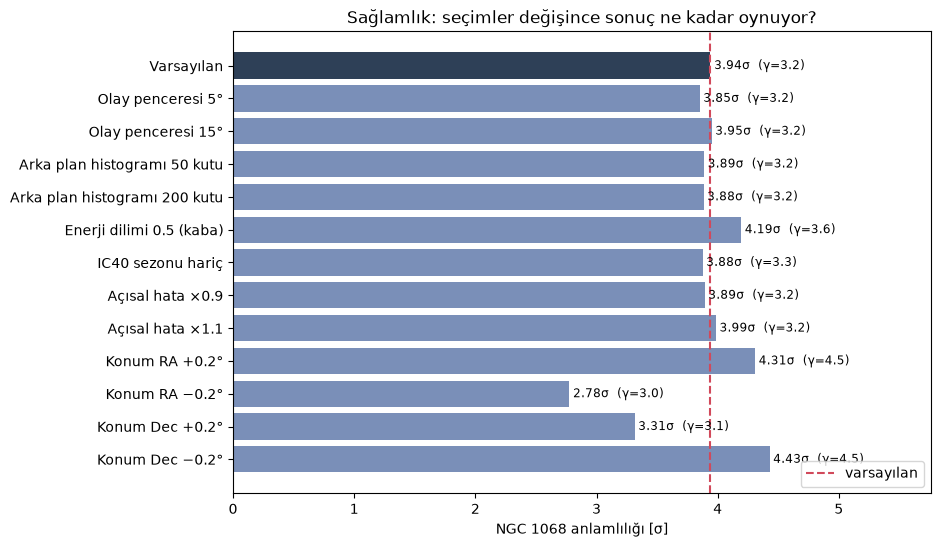

Anlamlılık aralığı: 2.78σ – 4.43σ   (varsayılan 3.94σ)
γ aralığı: 3.0 – 4.5


In [4]:
v = tablo15['sigma']
fig, ax = plt.subplots(figsize=(9, 6))
renk = ['#2e4057' if i == 0 else '#7a8fb8' for i in range(len(v))]
ax.barh(range(len(v))[::-1], v.values, color=renk)
ax.set_yticks(range(len(v))[::-1]); ax.set_yticklabels(v.index)
ax.axvline(v.iloc[0], color='#d1495b', ls='--', lw=1.5, label='varsayılan')
for i, (val, g) in enumerate(zip(v.values, tablo15['gamma'].values)):
    ax.text(val + 0.03, len(v) - 1 - i, f'{val:.2f}σ  (γ={g:.1f})', va='center', fontsize=8.5)
ax.set_xlabel('NGC 1068 anlamlılığı [σ]'); ax.set_xlim(0, max(v) * 1.3)
ax.set_title('Sağlamlık: seçimler değişince sonuç ne kadar oynuyor?'); ax.legend(loc='lower right')
plt.savefig(RESULTS / 'asama15_saglamlik.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Anlamlılık aralığı: {v.min():.2f}σ – {v.max():.2f}σ   (varsayılan {v.iloc[0]:.2f}σ)")
print(f"γ aralığı: {tablo15['gamma'].min():.1f} – {tablo15['gamma'].max():.1f}")

## Yorumlarken

- **Analiz seçimleri** (pencere, kutu sayıları) sonucu az oynatıyorsa, sonuç bizim keyfi tercihlerimizin bir ürünü değil.
- **Fiziksel belirsizlikler** bir **sistematik hata** payı verir: "anlamlılık 4σ ± (bu tablodaki oynama)". Gerçek bir makalede bu oynama "sistematik belirsizlik" olarak raporlanır.
- **IC40 hariç** testi, ilk yılların farklı dedektör konfigürasyonunun sonucu sürüklemediğini gösterir.
- Bir seçim sonucu **çok** değiştiriyorsa, o bir sorunun işaretidir ve raporda açıkça belirtilmelidir.